# Beam α + κ — post-crossmatch validation

**Role:** after a full-sky detect (with a probe-derived `beam_scale.json`) and
`radio_crossmatch.ipynb`, re-estimate `(α, κ)` and compare to the detect-time
prior. Optional VLSSR hybrid rescale of α is a **validation / refinement**
step here — not required to get a usable prior.

**Fast prior (before full detect):** use `beam_alpha_kappa_probe.ipynb`
(size-only on a Dec ladder of tiles, hybrid off).

See `.agents/plan-anisotropic-header-beam-alpha.md`.

**Inputs:** full-sky tile GAUL (`sources_healpix_tiles_*.parquet`) with
`Maj`/`Min`/`BMAJ`/`BMIN`/`DEC`/`S_Code`/`Peak_flux`/`band`; **spectral**
metacatalog with `Peak_flux_VLSSR` + `Total_flux_73MHz` for hybrid `s`
(fusion-only `metacatalog.parquet` has no VLSSR — hybrid will skip).

**Detect-time undo:** load this tree's `beam_scale.json` into
`BEAM_SCALE_USED` (per-band `{alpha, kappa}`). Catalog `BMAJ`/`BMIN` already
include that model; recovery is `Maj/header = α·E(δ)·Maj/BMAJ`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lwa_catalog.analyze import (
    BeamAlphaKappaEstimateConfig,
    estimate_beam_alpha_kappa,
    load_beam_scale,
    predict_total_flux_for_beam_scale,
    summarize_beam_alpha_kappa_estimate,
    write_beam_alpha_kappa_result,
)
from lwa_catalog.constants import OVRO_LATITUDE_DEG
from lwa_catalog.create.beam_scale_model import BeamScaleModel
from lwa_catalog.io import read_table
from lwa_catalog.paths import CatalogLayout
from lwa_catalog import read_metacatalog

CATALOG_DIR = Path("/fast/claw/metacatalog_healpix_IdTR-0.75s_subband5")
# Prefer this tree's detect-time beam_scale.json (per-band α,κ). Override only
# if the JSON is missing / wrong (e.g. scalar 1.2 from an older tree).
BEAM_SCALE_USED = None  # None → load from CATALOG_DIR/beam_scale.json
# Validation: hybrid on when metacatalog_spectral has Peak_flux_VLSSR.
# Size-only re-estimate still useful if spectral is missing.
APPLY_VLSSR_HYBRID = True
WRITE_OUTPUT = False  # True only to overwrite beam_scale.json after QA
BANDS = None  # or tuple of band labels
COMPARE_BAND = "73MHz"  # Peak/Total comparison band

layout = CatalogLayout(CATALOG_DIR)
if BEAM_SCALE_USED is None:
    BEAM_SCALE_USED = load_beam_scale(layout)
print(f"beam_scale_used type={type(BEAM_SCALE_USED).__name__}")
if isinstance(BEAM_SCALE_USED, dict):
    sample = next(iter(BEAM_SCALE_USED.items()))
    print(f"  sample {sample[0]} → {sample[1]}")

tile_paths = sorted(CATALOG_DIR.glob("sources_healpix_tiles_*.parquet"))
print(f"tile catalogs: {len(tile_paths)}")
frames = [read_table(p) for p in tile_paths]
sources = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print(f"sources rows: {len(sources):,}")

meta = None
spec = layout.metacatalog_spectral()
fus = layout.metacatalog()
meta_path = spec if spec.is_file() else fus
if meta_path.is_file() and APPLY_VLSSR_HYBRID:
    meta = read_metacatalog(meta_path, quality_mask=None)
    has_vlssr = "Peak_flux_VLSSR" in meta.columns
    print(
        f"VLSSR metacatalog: {meta_path.name} rows={len(meta):,} "
        f"Peak_flux_VLSSR={'yes' if has_vlssr else 'NO — hybrid will skip'}"
    )
    if not has_vlssr:
        print(
            "  Tip: fusion metacatalog has no survey attach. Run "
            "radio_crossmatch.ipynb → metacatalog_spectral.parquet, or set "
            "APPLY_VLSSR_HYBRID=False."
        )


beam_scale_used type=dict
  sample 18MHz → BeamScaleModel(alpha=1.2376374624542257, kappa=0.008794590836612834, model='zenith_south', phi_deg=37.239777)
tile catalogs: 15
sources rows: 2,131,990
VLSSR metacatalog: metacatalog.parquet rows=194,373 Peak_flux_VLSSR=NO — hybrid will skip
  Tip: fusion metacatalog has no survey attach. Run radio_crossmatch.ipynb → metacatalog_spectral.parquet, or set APPLY_VLSSR_HYBRID=False.


In [2]:
config = BeamAlphaKappaEstimateConfig(
    beam_scale_used=BEAM_SCALE_USED,
    apply_vlssr_hybrid=APPLY_VLSSR_HYBRID,
    bands=BANDS,
)
result = estimate_beam_alpha_kappa(
    sources, config=config, metacatalog_vlssr=meta
)
print(summarize_beam_alpha_kappa_estimate(result))
display(result.by_band)

# Side-by-side used (detect) vs re-estimated α
if isinstance(BEAM_SCALE_USED, dict):
    used_alpha = {
        b: float(m.alpha) if isinstance(m, BeamScaleModel) else float(m)
        for b, m in BEAM_SCALE_USED.items()
    }
    used_kappa = {
        b: float(m.kappa) if isinstance(m, BeamScaleModel) else 0.0
        for b, m in BEAM_SCALE_USED.items()
    }
else:
    m0 = (
        BEAM_SCALE_USED
        if isinstance(BEAM_SCALE_USED, BeamScaleModel)
        else BeamScaleModel.isotropic(float(BEAM_SCALE_USED))
    )
    used_alpha = {b: m0.alpha for b in result.by_band["band"]}
    used_kappa = {b: m0.kappa for b in result.by_band["band"]}

cmp = result.by_band.copy()
cmp["alpha_used"] = cmp["band"].map(used_alpha)
cmp["kappa_used"] = cmp["band"].map(used_kappa)
cmp["d_alpha"] = cmp["alpha"] - cmp["alpha_used"]
print("used vs estimated α (size-only; hybrid may rescale further):")
display(cmp[["band", "alpha_used", "alpha_size", "alpha", "d_alpha", "kappa_used", "kappa"]])

if WRITE_OUTPUT:
    path = write_beam_alpha_kappa_result(result, layout)
    print("wrote", path.resolve())


shared κ=0.00837897 deg⁻¹  (φ=37.240°, W=±20°)
beam_scale_used=per-band α∈[1.12,1.269] κ≈0.008795 (n=15)  VLSSR α scale factor s=1
  18MHz: α=1.374 (size 1.374)  n_zenith=8802 n_south=8089
  23MHz: α=1.372 (size 1.372)  n_zenith=13679 n_south=12769
  27MHz: α=1.383 (size 1.383)  n_zenith=19483 n_south=18375
  32MHz: α=1.401 (size 1.401)  n_zenith=26076 n_south=24250
  36MHz: α=1.39 (size 1.39)  n_zenith=29818 n_south=26871
  41MHz: α=1.332 (size 1.332)  n_zenith=32526 n_south=29721
  46MHz: α=1.323 (size 1.323)  n_zenith=31071 n_south=28319
  50MHz: α=1.308 (size 1.308)  n_zenith=29278 n_south=26466
  55MHz: α=1.31 (size 1.31)  n_zenith=26523 n_south=23713
  59MHz: α=1.325 (size 1.325)  n_zenith=23362 n_south=20589
  64MHz: α=1.289 (size 1.289)  n_zenith=22484 n_south=19896
  69MHz: α=1.272 (size 1.272)  n_zenith=19411 n_south=17107
  73MHz: α=1.292 (size 1.292)  n_zenith=16742 n_south=14691
  78MHz: α=1.311 (size 1.311)  n_zenith=14155 n_south=12425
  82MHz: α=1.317 (size 1.317)  n_ze

,band,alpha,alpha_size,kappa,n_zenith,n_south,med_maj_over_bmaj_zenith,med_min_over_bmin_zenith
0,18MHz,1.374054,1.374054,0.008379,8802,8089,1.374054,1.227731
1,23MHz,1.372129,1.372129,0.008379,13679,12769,1.372129,1.228062
2,27MHz,1.383368,1.383368,0.008379,19483,18375,1.383368,1.248726
3,32MHz,1.400766,1.400766,0.008379,26076,24250,1.400766,1.271054
4,36MHz,1.390376,1.390376,0.008379,29818,26871,1.390376,1.283339
5,41MHz,1.332307,1.332307,0.008379,32526,29721,1.332307,1.231800
6,46MHz,1.323417,1.323417,0.008379,31071,28319,1.323417,1.238703
7,50MHz,1.308314,1.308314,0.008379,29278,26466,1.308314,1.253273
8,55MHz,1.310227,1.310227,0.008379,26523,23713,1.310227,1.270881
9,59MHz,1.325349,1.325349,0.008379,23362,20589,1.325349,1.285898


used vs estimated α (size-only; hybrid may rescale further):


,band,alpha_used,alpha_size,alpha,d_alpha,kappa_used,kappa
0,18MHz,1.237637,1.374054,1.374054,0.136417,0.008795,0.008379
1,23MHz,1.238636,1.372129,1.372129,0.133493,0.008795,0.008379
2,27MHz,1.240508,1.383368,1.383368,0.142860,0.008795,0.008379
3,32MHz,1.264404,1.400766,1.400766,0.136363,0.008795,0.008379
4,36MHz,1.268660,1.390376,1.390376,0.121716,0.008795,0.008379
5,41MHz,1.183997,1.332307,1.332307,0.148310,0.008795,0.008379
6,46MHz,1.167113,1.323417,1.323417,0.156304,0.008795,0.008379
7,50MHz,1.147405,1.308314,1.308314,0.160909,0.008795,0.008379
8,55MHz,1.163111,1.310227,1.310227,0.147115,0.008795,0.008379
9,59MHz,1.185692,1.325349,1.325349,0.139657,0.008795,0.008379


## Peak / Total under used vs estimated `(α, κ)`

Catalog `Total_flux` was fit with the **detect-time** beam. Peak (image-plane
amplitude) is independent of the attached beam to first order; Total scales as
`Peak × (Maj×Min)/(BMAJ×BMIN)` with `BMAJ∝α·E(δ;κ)`, `BMIN∝α`. The curves below
hold fitted Peak/Maj/Min fixed and **predict** Total under the re-estimated
`(α, κ)` without re-detecting — so you can see how far the initial guess sits
from size/photometry consistency (`Total/Peak→1` when Maj≈BMAJ and Min≈BMIN).


73MHz: compact S Peak≥1 → 26,464 rows
zenith |δ−φ|≤20° n=15,149  med Total/Peak used=1.239  pred@est=0.978  med Maj/BMAJ=1.094


,band,alpha_used,alpha_est,med_peak_zen,med_tp_used_zen,med_tp_est_zen,n_zen
0,18MHz,1.237637,1.374054,8.998310,1.085915,0.881890,7952
1,23MHz,1.238636,1.372129,6.159722,1.085186,0.885431,12231
2,27MHz,1.240508,1.383368,3.899544,1.101745,0.887115,17438
3,32MHz,1.264404,1.400766,2.693460,1.086607,0.886450,23378
4,36MHz,1.268660,1.390376,2.178682,1.089799,0.908508,26850
5,41MHz,1.183997,1.332307,2.006056,1.156170,0.914466,29243
6,46MHz,1.167113,1.323417,1.875675,1.189292,0.926297,27942
7,50MHz,1.147405,1.308314,1.749470,1.232498,0.949183,26286
8,55MHz,1.163111,1.310227,1.652380,1.220336,0.962900,23855
9,59MHz,1.185692,1.325349,1.592404,1.199336,0.961170,21059


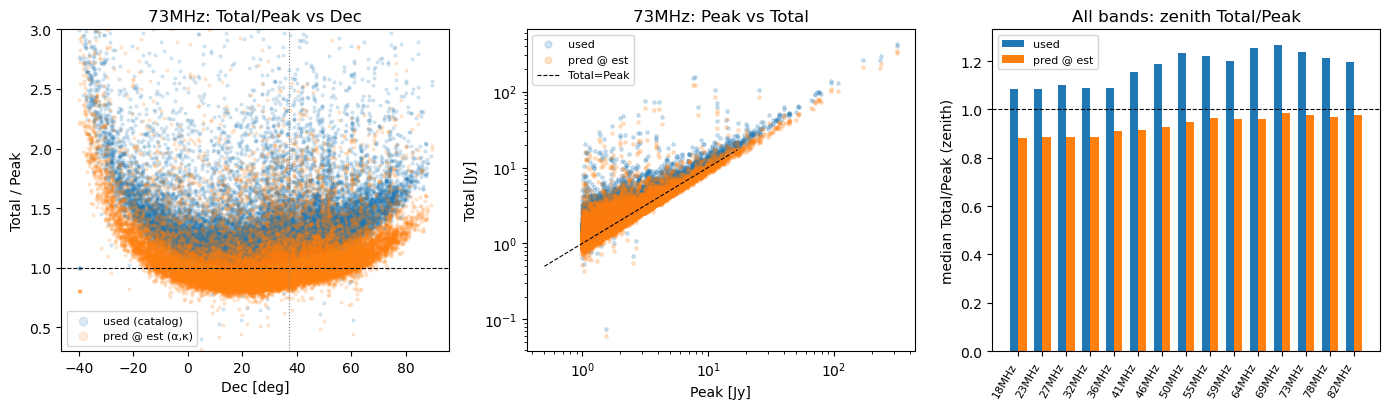

In [3]:
band = COMPARE_BAND
sub = sources.loc[sources["band"].astype(str) == band].copy()
if "S_Code" in sub.columns:
    sub = sub.loc[sub["S_Code"].astype(str) == "S"]
sub = sub.loc[pd.to_numeric(sub["Peak_flux"], errors="coerce") >= 1.0]
print(f"{band}: compact S Peak≥1 → {len(sub):,} rows")

estimated_map = result.as_mapping()
sub["Total_pred"] = predict_total_flux_for_beam_scale(
    sub,
    beam_scale_used=BEAM_SCALE_USED,
    beam_scale_new=estimated_map,
    phi_deg=OVRO_LATITUDE_DEG,
)
sub["tp_used"] = pd.to_numeric(sub["Total_flux"], errors="coerce") / pd.to_numeric(
    sub["Peak_flux"], errors="coerce"
)
sub["tp_est"] = sub["Total_pred"] / pd.to_numeric(sub["Peak_flux"], errors="coerce")
sub["maj_over"] = pd.to_numeric(sub["Maj"], errors="coerce") / pd.to_numeric(
    sub["BMAJ"], errors="coerce"
)
dec = pd.to_numeric(sub["DEC"], errors="coerce")
zen = (dec - OVRO_LATITUDE_DEG).abs() <= 20.0

print(
    f"zenith |δ−φ|≤20° n={int(zen.sum()):,}  "
    f"med Total/Peak used={sub.loc[zen, 'tp_used'].median():.3f}  "
    f"pred@est={sub.loc[zen, 'tp_est'].median():.3f}  "
    f"med Maj/BMAJ={sub.loc[zen, 'maj_over'].median():.3f}"
)

# Per-band summary: used vs estimated α and zenith Total/Peak
rows = []
for b, row in result.by_band.set_index("band").iterrows():
    sb = sources.loc[sources["band"].astype(str) == str(b)].copy()
    if "S_Code" in sb.columns:
        sb = sb.loc[sb["S_Code"].astype(str) == "S"]
    sb = sb.loc[pd.to_numeric(sb["Peak_flux"], errors="coerce") >= 1.0]
    if sb.empty:
        continue
    pred = predict_total_flux_for_beam_scale(
        sb,
        beam_scale_used=BEAM_SCALE_USED,
        beam_scale_new=estimated_map,
        phi_deg=OVRO_LATITUDE_DEG,
    )
    d = pd.to_numeric(sb["DEC"], errors="coerce")
    z = (d - OVRO_LATITUDE_DEG).abs() <= 20.0
    peak = pd.to_numeric(sb["Peak_flux"], errors="coerce")
    tot = pd.to_numeric(sb["Total_flux"], errors="coerce")
    rows.append(
        {
            "band": b,
            "alpha_used": used_alpha.get(str(b), np.nan),
            "alpha_est": float(row["alpha"]),
            "med_peak_zen": float(peak.loc[z].median()),
            "med_tp_used_zen": float((tot / peak).loc[z].median()),
            "med_tp_est_zen": float((pred / peak).loc[z].median()),
            "n_zen": int(z.sum()),
        }
    )
flux_cmp = pd.DataFrame(rows)
display(flux_cmp)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

# 1) Total/Peak vs Dec (used vs predicted)
ax = axes[0]
ax.scatter(dec, sub["tp_used"], s=4, alpha=0.15, label="used (catalog)", c="C0")
ax.scatter(dec, sub["tp_est"], s=4, alpha=0.15, label="pred @ est (α,κ)", c="C1")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.axvline(OVRO_LATITUDE_DEG, color="0.5", lw=0.8, ls=":")
ax.set_xlabel("Dec [deg]")
ax.set_ylabel("Total / Peak")
ax.set_title(f"{band}: Total/Peak vs Dec")
ax.set_ylim(0.3, 3.0)
ax.legend(markerscale=3, fontsize=8)

# 2) Peak vs Total (used and predicted)
ax = axes[1]
peak = pd.to_numeric(sub["Peak_flux"], errors="coerce")
ax.scatter(peak, pd.to_numeric(sub["Total_flux"], errors="coerce"), s=6, alpha=0.2, label="used", c="C0")
ax.scatter(peak, sub["Total_pred"], s=6, alpha=0.2, label="pred @ est", c="C1")
lim = np.nanpercentile(peak, 99.5)
ax.plot([0.5, lim], [0.5, lim], "k--", lw=0.8, label="Total=Peak")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Peak [Jy]")
ax.set_ylabel("Total [Jy]")
ax.set_title(f"{band}: Peak vs Total")
ax.legend(markerscale=2, fontsize=8)

# 3) Per-band median zenith Total/Peak
ax = axes[2]
x = np.arange(len(flux_cmp))
aw = 0.35
ax.bar(x - aw / 2, flux_cmp["med_tp_used_zen"], width=aw, label="used", color="C0")
ax.bar(x + aw / 2, flux_cmp["med_tp_est_zen"], width=aw, label="pred @ est", color="C1")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xticks(x)
ax.set_xticklabels(flux_cmp["band"], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("median Total/Peak (zenith)")
ax.set_title("All bands: zenith Total/Peak")
ax.legend(fontsize=8)

fig.tight_layout()
plt.show()
